# De las trayectorias macro a las tasas de pérdida: trayectorias de escenario, satélites y una severidad t asimétrica

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema; los cuadernos 02 y 03 no hacen falta
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir de qué se compone una prueba de estrés macro (una trayectoria de escenario, modelos satélite y un motor de capital) y cuál de las tres cubre este cuaderno;
- leer la añada y el proveedor de cada uno de los cuatro escenarios del caso y ver al motor rechazar una trayectoria publicada después de la fecha de observación;
- trasladar una trayectoria publicada al punto de partida del banco: la trayectoria de la Reserva Federal tal cual, la trayectoria anual de la EBA convertida a trimestres y la trayectoria de desviaciones de la NGFS sumada a su base, cada una recalculada con las funciones de trayectoria del motor y comparada con la versionada;
- leer una regresión satélite, proyectarla bajo un escenario a mano para un trimestre y con `project_scenario` para doce, y obtener las tasas de pérdida versionadas y la pérdida de crédito de cada año;
- ejecutar la mecánica de dos herramientas de escenario más del motor, el pronóstico condicional de un VAR y el ajuste t asimétrico de Azzalini y Capitanio del crecimiento en riesgo, y decir qué necesita cada una que los archivos versionados no tienen.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los textos propios del motor (identificadores de pruebas, mensajes, notas y docstrings) se imprimen tal como los escribe el motor, en inglés, en ambos árboles.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.stress import paths, satellites, scenario_models
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee el lado de escenarios de **C18** (Banco Andino): cuatro variantes de escenario y el documento de modelos de los satélites.

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** los cuatro documentos de variante `data/derived/C18/baseline.json` y `fed-2026-severely-adverse.json` (Reserva Federal 2026, trimestral), `eba-2025-adverse.json` (EBA y ESRB 2025, anual, filas de Estados Unidos) y `ngfs-delayed-transition.json` (NGFS Fase V, desviaciones de NiGEM respecto de la corrida base, anual), y el documento de modelos `data/derived/C18/models-banco-andino.json` (los satélites ajustados: coeficientes, errores estándar, ventanas de muestra). El `outputs.scenario` de cada variante tiene la trayectoria publicada, su traslado y su añada; `outputs.satellites` las tasas proyectadas; `outputs.losses` la pérdida de crédito por año; `outputs.backcast` las tasas realizadas de 2020 a 2025.
- **Lo que no está versionado:** la historia de la Reserva Federal de 1985 a 2019 y las series de castigos con que se ajustaron los satélites. El paso 5 por lo tanto **proyecta** los satélites ajustados con los coeficientes versionados, pero no puede **reajustarlos**; el ajuste es `fit_satellite`, que corre el pipeline sobre los archivos crudos.
- **La adaptación, declarada.** Las trayectorias son de Estados Unidos y de la zona euro; Banco Andino es chileno y sintético. Cada trayectoria se traslada al valor de partida propio del banco y los satélites se ajustan sobre tasas de castigo de Estados Unidos, así que toda tasa de pérdida de este cuaderno lleva en los documentos el rótulo `us-calibrated-adaptation`. Enseña la maquinaria, no un pronóstico para Chile.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("carpeta derived encontrada:", DERIVED.is_dir())

VARIANTS = {"baseline": "baseline", "eba": "eba-2025-adverse", "fed": "fed-2026-severely-adverse", "ngfs": "ngfs-delayed-transition"}
docs = {key: read_json(f"C18/{name}.json") for key, name in VARIANTS.items()}
models = read_json("C18/models-banco-andino.json")["fit"]
AS_OF = docs["baseline"]["outputs"]["bank"]["as_of"]
print("variantes:", list(VARIANTS.values()), "| fecha de observación del banco:", AS_OF)

carpeta derived encontrada: True
variantes: ['baseline', 'eba-2025-adverse', 'fed-2026-severely-adverse', 'ngfs-delayed-transition'] | fecha de observación del banco: 2026-08-31


## Método

### Paso 1: los escenarios y su añada

Una prueba de estrés macro tiene tres capas (dossier 05, H.1): un **generador de escenarios** de trayectorias macrofinancieras a un horizonte de dos a tres años, **modelos satélite** que llevan las trayectorias a parámetros de riesgo, y un **motor de capital** que convierte pérdidas e ingresos en razones de capital (cuaderno 05). Este cuaderno cubre las dos primeras.

Cada escenario es un documento publicado con una fecha, su **añada**. Un escenario publicado después de la fecha en que se observa un modelo dejaría entrar el futuro en la validación, así que `check_vintage` del motor rechaza una trayectoria cuya añada es posterior a la fecha de observación y acepta fechas iguales. La celda siguiente imprime proveedor, documento, añada y variables de cada uno de los cuatro escenarios, comprueba cada añada contra la fecha de observación del banco y muestra el rechazo de una trayectoria fechada un mes después.

In [3]:
# Imprimir proveedor, añada y variables de cada escenario, comprobar la añada con el motor y mostrar un rechazo
for key, doc in docs.items():
    scenario = doc["outputs"]["scenario"]
    paths.check_vintage(scenario["vintage_date"], AS_OF)
    print(f'{scenario["scenario_id"]:27s} proveedor {scenario["provider"]:9s} añada {scenario["vintage_date"]} | variables: {[p["maps_to_regressor"] for p in scenario["paths"]]}')
print("las cuatro añadas son iguales o anteriores a", AS_OF)
try:
    paths.check_vintage("2026-09-30", AS_OF)
except ValueError as err:
    print("una trayectoria fechada 2026-09-30 se rechaza:", err)

baseline                    proveedor fed       añada 2026-02-04 | variables: ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
eba-2025-adverse            proveedor eba-esrb  añada 2025-02-26 | variables: ['real_gdp_growth', 'unemployment_rate', 'treasury_10y']
fed-2026-severely-adverse   proveedor fed       añada 2026-02-04 | variables: ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
ngfs-delayed-transition     proveedor ngfs      añada 2024-11-01 | variables: ['unemployment_rate', 'prime_rate', 'treasury_10y', 'real_gdp_growth']
las cuatro añadas son iguales o anteriores a 2026-08-31
una trayectoria fechada 2026-09-30 se rechaza: the vintage 2026-09-30 postdates the observation date 2026-08-31


### Paso 2: la forma de una trayectoria sobre el punto de partida del banco

Los satélites parten del último trimestre observado del banco, 2025 T4, no de la fecha de partida propia del escenario. El motor por lo tanto **traslada** una trayectoria publicada al destino: se conserva la forma de la trayectoria, su cambio desde su punto de partida propio, y se suma al último valor observado del banco (decisión Q6 del caso),

$$\tilde x_t = x^{\text{destino}}_{0} + \left(x_t - x^{\text{origen}}_{0}\right), \qquad t = 1, \dots, 12,$$

que implementa `transpose_path(levels, source_jump_off, target_value, n)`. Para los escenarios de la Reserva Federal el punto de partida de origen es 2025 T4 y el destino es el mismo trimestre, de modo que el traslado no cambia nada: la primera prueba de la maquinaria es que devuelva la trayectoria publicada. La celda siguiente toma la tasa de desempleo del escenario severamente adverso, imprime los trimestres publicados, traslada con el motor y compara con la trayectoria trasladada versionada.

In [4]:
# Trasladar con el motor la trayectoria de desempleo severamente adversa de la Reserva Federal y compararla con la versionada
def path_of(key, regressor):
    return next(p for p in docs[key]["outputs"]["scenario"]["paths"] if p["maps_to_regressor"] == regressor)


unemployment = path_of("fed", "unemployment_rate")
levels = np.array([row["value"] for row in unemployment["levels"]])
jump, target = unemployment["transposition"]["source_jump_off"]["value"], unemployment["transposition"]["target"]["value"]
transposed = paths.transpose_path(levels, jump, target, 12)
committed_path = np.array([row["value"] for row in unemployment["transposed"]])
print("trimestres publicados (13):", levels)
print("punto de partida de origen:", jump, "| destino:", target, "| trasladada (12):", np.round(transposed, 2))
print("igual a la trayectoria trasladada versionada:", bool(np.allclose(transposed, committed_path)), "| primer trimestre publicado:", unemployment["source"][0]["date"])

trimestres publicados (13): [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4  8. ]
punto de partida de origen: 4.5 | destino: 4.5 | trasladada (12): [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4]
igual a la trayectoria trasladada versionada: True | primer trimestre publicado: 2026-03-31


### Paso 3: la trayectoria de la EBA, de anual a trimestral

La EBA y la ESRB publican niveles anuales solo para 2025, 2026 y 2027. Los satélites son trimestrales, así que `annual_to_quarterly(year_end_levels, jump_off_level)` une los niveles de fin de año linealmente desde el nivel de partida: el trimestre $k$ de un año es $\text{prev} + (\text{cur} - \text{prev})\,k/4$, y el cuarto trimestre es el nivel de fin de año mismo. Si los valores del libro son promedios anuales o valores de fin de año es NO VERIFICADO en el registro de la investigación, y el motor los trata como niveles de fin de año. El punto de partida del escenario de la EBA es 2024 T4 (el año base del ejercicio), mientras que el del banco es 2025 T4, así que ahora el traslado importa: la forma se conserva y se suma al valor de 2025 T4 del banco. La celda siguiente convierte y traslada con el motor las trayectorias de desempleo y de crecimiento del PIB, imprime las trayectorias trimestrales intermedias del desempleo y compara con el traslado versionado.

In [5]:
# Convertir los niveles anuales de la EBA a trimestres, trasladar al punto de partida del banco y comparar con la trayectoria versionada
for regressor in ("unemployment_rate", "real_gdp_growth"):
    p = path_of("eba", regressor)
    year_end = np.array([row["value"] for row in p["levels"]])
    source_jump, target = p["transposition"]["source_jump_off"]["value"], p["transposition"]["target"]["value"]
    quarterly = paths.annual_to_quarterly(year_end, source_jump)
    moved = paths.transpose_path(quarterly, source_jump, target, 12)
    committed_moved = np.array([row["value"] for row in p["transposed"]])
    print(f"{regressor}: niveles de fin de año {np.round(year_end, 3)} | partida de origen {source_jump:.3f} a destino {target}")
    if regressor == "unemployment_rate":
        print("  trimestral (annual_to_quarterly):", np.round(quarterly, 3))
    print("  trasladada:", np.round(moved, 3), "| igual a la trayectoria versionada:", bool(np.allclose(moved, committed_moved)))

unemployment_rate: niveles de fin de año [ 8.914 10.046  8.647] | partida de origen 4.081 a destino 4.5
  trimestral (annual_to_quarterly): [ 5.289  6.497  7.705  8.914  9.197  9.48   9.763 10.046  9.696  9.346
  8.997  8.647]
  trasladada: [ 5.708  6.916  8.125  9.333  9.616  9.899 10.182 10.465 10.115  9.766
  9.416  9.066] | igual a la trayectoria versionada: True
real_gdp_growth: niveles de fin de año [-5.055 -2.454  4.28 ] | partida de origen 2.765 a destino 1.0
  trasladada: [-0.955 -2.91  -4.865 -6.82  -6.169 -5.519 -4.869 -4.219 -2.535 -0.852
  0.832  2.515] | igual a la trayectoria versionada: True


### Paso 4: la trayectoria de la NGFS, una desviación de una corrida base

Las corridas de la NGFS Fase V publican, para cada escenario, la **desviación** respecto de la corrida Base, así que el nivel de un escenario es el nivel base más la desviación (una diferencia porcentual para el PIB): `level_from_deviation(baseline, deviation, kind)` con `kind` igual a `plus` o `percent`. El choque de política de la transición tardía actúa en **2031 a 2033** en las corridas de la NGFS, así que el caso toma esos tres años y los traslada al punto de partida de 2025 T4 del banco: la forma del choque, no su calendario. La celda siguiente reconstruye los niveles de desempleo y de tasa de política a partir de la corrida base y la desviación, convierte a trimestres con el punto de partida de 2030, traslada al banco y compara con la trayectoria versionada.

Una trayectoria publicada termina en un horizonte; los satélites pueden necesitar más trimestres. `revert_to_baseline(path, baseline_tail, n, reversion_quarters)` extiende una trayectoria más allá de su final llevándola linealmente de vuelta a la cola base en `reversion_quarters` pasos (una convención del caso, 12). La celda cierra extendiendo a 24 trimestres la trayectoria de desempleo severamente adversa del paso 2, que el horizonte versionado de 12 trimestres no usa.

In [6]:
# Reconstruir los niveles de la NGFS como base + desviación, convertir, trasladar, comparar; y extender una trayectoria con la regla de reversión
for regressor in ("unemployment_rate", "prime_rate"):
    p = path_of("ngfs", regressor)
    baseline_run = np.array([row["value"] for row in p["level_rule"]["baseline"]])
    deviation = np.array([row["value"] for row in p["source"]])
    rebuilt = paths.level_from_deviation(baseline_run, deviation, "plus")
    source_jump, target = p["transposition"]["source_jump_off"]["value"], p["transposition"]["target"]["value"]
    moved = paths.transpose_path(paths.annual_to_quarterly(rebuilt, source_jump), source_jump, target, 12)
    committed_moved = np.array([row["value"] for row in p["transposed"]])
    print(f"{regressor}: corrida base {np.round(baseline_run, 3)} + desviación {np.round(deviation, 3)} = {np.round(rebuilt, 3)}")
    print("  igual a los niveles versionados:", bool(np.allclose(rebuilt, [row["value"] for row in p["levels"]])), "| la trasladada iguala la trayectoria versionada:", bool(np.allclose(moved, committed_moved)))
window = docs["ngfs"]["outputs"]["scenario"]["policy_shock_window"]
print("ventana del choque de política:", window["start_year"], "a", window["end_year"])
baseline_tail = path_of("baseline", "unemployment_rate")["transposed"][-1]["value"]
extended = paths.revert_to_baseline(transposed, baseline_tail, 24, 12)
print("desempleo severamente adverso extendido a 24 trimestres, con reversión hacia", baseline_tail, ":", np.round(extended[10:], 2))

unemployment_rate: corrida base [4.442 4.494 4.537] + desviación [0.106 0.408 0.324] = [4.547 4.902 4.861]
  igual a los niveles versionados: True | la trasladada iguala la trayectoria versionada: True
prime_rate: corrida base [3.25 3.25 3.25] + desviación [ 0.03  -0.57  -0.603] = [3.28  2.68  2.647]
  igual a los niveles versionados: True | la trasladada iguala la trayectoria versionada: True
ventana del choque de política: 2031 a 2033
desempleo severamente adverso extendido a 24 trimestres, con reversión hacia 4.3 : [8.7  8.4  8.06 7.72 7.38 7.03 6.69 6.35 6.01 5.67 5.32 4.98 4.64 4.3 ]


### Paso 5: un satélite, a mano y con el motor

Un satélite explica la tasa de pérdida $DR_t$ de un tipo de préstamo por las variables macro, a través de un enlace $g$ (dossier 04, I.1 y dossier 05, H.1 capa 2):

$$g(DR_t) = \alpha + \sum_{k=1}^{p}\phi_k\, g(DR_{t-k}) + \sum_{j,\ell}\beta_{j\ell}\, X_{j,t-\ell} + \varepsilon_t.$$

Con el enlace **probit**, $g = \Phi^{-1}$, la regresión es una regresión del ciclo crediticio latente del modelo de un factor de Vasicek sobre las variables macro, razón por la cual el enlace es consistente con los modelos de cartera del tema 06. Los segmentos cuya tasa es cero o negativa en algunos trimestres (recuperaciones netas de bienes raíces) usan el enlace identidad. En el caso $p = 1$, los regresores son el crecimiento del PIB real y la tasa de desempleo con rezagos 0 y 1, y cada satélite se ajusta por mínimos cuadrados ordinarios sobre 1985 a 2019 (1991 a 2019 para los dos tipos de bienes raíces).

La celda siguiente lee los coeficientes versionados del satélite comercial e industrial, toma la última tasa realizada (2025 T4, del bloque de retroproyección) y calcula **el primer trimestre proyectado a mano**: el enlace de la última tasa, cada término de la ecuación, la suma y el enlace inverso. Luego llama a `project_scenario` para los doce trimestres y para los cinco tipos de préstamo bajo el escenario severamente adverso de la Reserva Federal, y compara con las tasas versionadas.

In [7]:
# El primer trimestre proyectado del satélite comercial e industrial a mano, y luego project_scenario para los cinco tipos de préstamo
fed_paths = {p["maps_to_regressor"]: p for p in docs["fed"]["outputs"]["scenario"]["paths"]}
X = np.column_stack([[row["value"] for row in fed_paths[name]["transposed"]] for name in ("real_gdp_growth", "unemployment_rate")])
jump_off = np.array([[fed_paths[name]["transposition"]["target"]["value"] for name in ("real_gdp_growth", "unemployment_rate")]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in docs["fed"]["outputs"]["backcast"]["per_loan_type"]}
committed_rates = {t["fed_loan_type"]: np.array([q["rate"] for q in t["quarters"]]) for t in docs["fed"]["outputs"]["satellites"]["fed_loan_types"]}


def satellite_fit(model):
    names = []
    for regressor in model["regressors"]:
        if regressor["name"] not in names:
            names.append(regressor["name"])
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"], n_obs=model["n_obs"],
        ar_order=model["ar_order"], regressor_names=tuple(names), lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in model["coefficients"]), estimates=tuple(c["estimate"] for c in model["coefficients"]),
        std_errors=tuple(c["std_error"] for c in model["coefficients"]), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


ci = next(m for m in models["satellites"] if m["fed_loan_type"] == "commercial-industrial")
coef = {c["name"]: c["estimate"] for c in ci["coefficients"]}
g0 = satellites.link("probit", np.array([last_rate["commercial-industrial"]]))[0]
terms = {"intercepto": coef["intercept"], "ar_1 * g(última tasa)": coef["ar_1"] * g0,
         "crecimiento del PIB, rezago 0": coef["real_gdp_growth_lag0"] * X[0, 0], "crecimiento del PIB, rezago 1": coef["real_gdp_growth_lag1"] * jump_off[0, 0],
         "desempleo, rezago 0": coef["unemployment_rate_lag0"] * X[0, 1], "desempleo, rezago 1": coef["unemployment_rate_lag1"] * jump_off[0, 1]}
print("última tasa realizada (2025 T4):", last_rate["commercial-industrial"], "| valor del enlace probit:", round(float(g0), 4))
for name, value in terms.items():
    print(f"  {name:30s} {value:9.4f}")
by_hand = float(satellites.inverse_link("probit", np.array([sum(terms.values())]))[0])
print("suma de los términos:", round(sum(terms.values()), 4), "| enlace inverso (tasa):", round(by_hand, 6), "| primer trimestre versionado:", round(float(committed_rates["commercial-industrial"][0]), 6))
for model in models["satellites"]:
    fit = satellite_fit(model)
    projection = satellites.project_scenario(fit, satellites.link(fit.link, np.array([last_rate[model["fed_loan_type"]]])), jump_off, X)
    gap = float(np.max(np.abs(projection.rates - committed_rates[model["fed_loan_type"]])))
    print(f'{model["fed_loan_type"]:24s} enlace {fit.link:8s} n_obs {fit.n_obs:3d} R2 {fit.r_squared:.3f} | tasa proyectada máxima {projection.rates.max():.4f} | brecha máxima con las tasas versionadas {gap:.1e}')

última tasa realizada (2025 T4): 0.005600000000000001 | valor del enlace probit: -2.5364
  intercepto                       -0.0269
  ar_1 * g(última tasa)            -2.4236
  crecimiento del PIB, rezago 0    -0.0038
  crecimiento del PIB, rezago 1    -0.0074
  desempleo, rezago 0               0.4169
  desempleo, rezago 1              -0.3691
suma de los términos: -2.4138 | enlace inverso (tasa): 0.007894 | primer trimestre versionado: 0.007894
commercial-industrial    enlace probit   n_obs 139 R2 0.942 | tasa proyectada máxima 0.0180 | brecha máxima con las tasas versionadas 0.0e+00
commercial-real-estate   enlace identity n_obs 115 R2 0.959 | tasa proyectada máxima 0.0179 | brecha máxima con las tasas versionadas 0.0e+00
residential              enlace identity n_obs 115 R2 0.954 | tasa proyectada máxima 0.0114 | brecha máxima con las tasas versionadas 0.0e+00
credit-cards             enlace probit   n_obs 139 R2 0.926 | tasa proyectada máxima 0.0873 | brecha máxima con las tasas v

La proyección reproduce las tasas versionadas hasta el último dígito para los cinco tipos de préstamo, así que la trayectoria versionada es exactamente lo que da el motor a partir de los coeficientes y la trayectoria versionados.

**De los tipos de préstamo a la pérdida de crédito del banco.** La cartera de Banco Andino está en tres clases, cada una asignada a tipos de préstamo de la Reserva Federal con pesos fijos (una adaptación del caso): comercial = 0,6 C&I + 0,4 bienes raíces comerciales, consumo = 0,5 tarjetas de crédito + 0,5 otro consumo, hipotecario = residencial. La pérdida de crédito de un año es la exposición de cada clase por el promedio de las cuatro tasas trimestrales del año, sumada sobre las clases. La celda siguiente reconstruye las tasas de clase a partir de los pesos, las tres pérdidas de crédito anuales, y las compara con el bloque `losses` versionado.

In [8]:
# Tasas de clase a partir de los pesos por tipo de préstamo y la exposición, y la pérdida de crédito de cada año frente al bloque versionado
annual_loss = np.zeros(3)
for klass in docs["fed"]["outputs"]["satellites"]["banco_andino_classes"]:
    class_rate = sum(w * committed_rates[t] for t, w in zip(klass["maps_from"], klass["weights"]))
    committed_class = np.array([q["rate"] for q in klass["quarters"]])
    yearly = class_rate.reshape(3, 4).mean(axis=1) * klass["exposure_clp_m"]
    annual_loss += yearly
    print(f'{klass["banco_andino_class"]:11s} pesos {klass["weights"]} | exposición {klass["exposure_clp_m"]:12,.0f} | la tasa de clase iguala la versionada: {bool(np.allclose(class_rate, committed_class))} | pérdida anual {np.round(yearly, 0)}')
committed_loss = [row["credit"] for row in docs["fed"]["outputs"]["losses"]["scenario_losses"]]
print("pérdida de crédito por año aquí     :", np.round(annual_loss, 1))
print("pérdida de crédito por año versionada:", np.round(committed_loss, 1))

commercial  pesos [0.6, 0.4] | exposición    3,242,822 | la tasa de clase iguala la versionada: True | pérdida anual [40510. 54449. 31441.]
consumer    pesos [0.5, 0.5] | exposición      683,660 | la tasa de clase iguala la versionada: True | pérdida anual [30755. 34862. 23885.]
mortgage    pesos [1.0] | exposición    2,073,518 | la tasa de clase iguala la versionada: True | pérdida anual [15253. 22676. 15679.]
pérdida de crédito por año aquí     : [ 86518.6 111986.8  71005.1]
pérdida de crédito por año versionada: [ 86518.6 111986.8  71005.1]


### Paso 6: un VAR y un pronóstico condicional

Los satélites asocian dos variables macro elegidas con tasas de pérdida. Una **autorregresión vectorial** modela varias variables juntas, $y_t = c + \sum_{l=1}^{p} A_l\, y_{t-l} + u_t$ (dossier 05, H.2), y un escenario de estrés es entonces un **pronóstico condicional**: se da la trayectoria de un subconjunto de las variables y las otras se siguen del modelo, con los choques de las variables libres correlacionados con los de las condicionadas. `fit_var(y, lags)` la estima por MCO ecuación por ecuación y `var_conditional_forecast(fit, y_history, path, conditioned)` calcula las trayectorias condicionales (la forma período a período; la forma de horizonte completo de Waggoner y Zha es NO VERIFICADA contra el artículo).

El caso no hornea un VAR, y los archivos versionados no tienen historia macro para ajustar uno. Lo que sí tienen son tasas de castigo trimestrales reales de 2020 a 2025 (las tasas realizadas del bloque de retroproyección), así que la celda siguiente corre la **mecánica** sobre ellas: un VAR(1) de la tasa comercial e industrial y la tasa de tarjetas de crédito (24 trimestres, una muestra corta que solo una demostración puede permitirse), condicionado a que la tasa de tarjetas siga la proyección del satélite bajo el escenario severamente adverso. La salida es lo que haría la tasa C&I si las pérdidas de tarjetas siguieran esa trayectoria, para comparar con la proyección propia del satélite C&I. Es una ilustración de la herramienta, no un hallazgo.

In [9]:
# Un VAR(1) sobre las tasas realizadas C&I y de tarjetas de 2020-2025, condicionado a la trayectoria del satélite de la tasa de tarjetas
realised = {b["fed_loan_type"]: np.array([q["realised"] for q in b["quarters"]]) for b in docs["fed"]["outputs"]["backcast"]["per_loan_type"]}
y = np.column_stack([realised["commercial-industrial"], realised["credit-cards"]])
var_fit = scenario_models.fit_var(y, 1)
print("observaciones:", y.shape[0], "| intercepto:", np.round(var_fit.intercept, 5))
print("A_1 =", np.round(var_fit.coefficients[0], 3).tolist(), "| valores propios de A_1:", np.round(np.linalg.eigvals(var_fit.coefficients[0]), 3))
card_path = committed_rates["credit-cards"].reshape(-1, 1)
conditional = scenario_models.var_conditional_forecast(var_fit, y[-1:], card_path, [1])
print("tasa de tarjetas condicionada (satélite):", np.round(card_path[:6, 0], 4))
print("tasa C&I implícita en el VAR            :", np.round(conditional[:6, 0], 4))
print("tasa C&I del satélite                   :", np.round(committed_rates["commercial-industrial"][:6], 4))
print("la variable condicionada sigue su trayectoria exactamente:", bool(np.allclose(conditional[:, 1], card_path[:, 0])))

observaciones: 24 | intercepto: [-0.00076 -0.00047]
A_1 = [[0.493, 0.081], [-1.922, 1.238]] | valores propios de A_1: [0.865+0.128j 0.865-0.128j]
tasa de tarjetas condicionada (satélite): [0.055  0.0688 0.0788 0.0855 0.0872 0.0873]
tasa C&I implícita en el VAR            : [0.0067 0.0082 0.0097 0.011  0.0119 0.0124]
tasa C&I del satélite                   : [0.0079 0.0115 0.0148 0.0172 0.018  0.0179]
la variable condicionada sigue su trayectoria exactamente: True


### Paso 7: crecimiento en riesgo y la densidad t asimétrica

El **crecimiento en riesgo** (Adrian, Boyarchenko y Giannone 2019) construye toda una distribución predictiva del crecimiento del PIB en dos pasos. El paso 1 corre **regresiones cuantílicas** del crecimiento anualizado promedio sobre una constante, el crecimiento actual y un índice de condiciones financieras, una para cada cuantil de 5, 25, 75 y 95 por ciento. El paso 2 ajusta la densidad **t asimétrica de Azzalini y Capitanio**

$$f(y;\mu,\sigma,\alpha,\nu) = \frac{2}{\sigma}\, t\!\left(\frac{y-\mu}{\sigma};\nu\right) T\!\left(\alpha\,\frac{y-\mu}{\sigma}\sqrt{\frac{\nu+1}{\nu+\left(\frac{y-\mu}{\sigma}\right)^2}};\ \nu+1\right)$$

a los cuatro cuantiles estimados por mínimos cuadrados, donde $t$ y $T$ son la densidad y la función de distribución de la t de Student y $\alpha$ la asimetría ($\alpha = 0$ es la t de Student). Los cuantiles inferiores se mueven con fuerza con las condiciones financieras mientras los superiores son estables, lo que hace de la densidad ajustada un **calibrador de severidad** para escenarios.

El motor tiene ambos pasos. `gar_quantile_regressions` necesita `statsmodels` (el extra opcional `stress` del motor) y una serie de condiciones financieras; **ninguno está en el entorno del cuaderno ni en los archivos versionados**, así que el paso 1 no se corre aquí. El paso 2, `fit_skewed_t_to_quantiles`, solo necesita cuatro cuantiles, y la celda siguiente lo prueba de dos maneras. Primero, la densidad con $\alpha = 0$ debe igualar la t de Student e integrar 1. Segundo, un ajuste de verdad conocida: los cuantiles de una normal con la desviación estándar del crecimiento del PIB real de 1985 a 2019 (el `factor_space` versionado) deben devolver $\alpha \approx 0$ y un $\nu$ grande; luego un conjunto de cuantiles con cola inferior pesada, la forma que encuentra el crecimiento en riesgo en condiciones de estrés (múltiplos ilustrativos de esa desviación estándar), debe devolver un $\alpha$ negativo.

In [10]:
# Comprobar la densidad t asimétrica contra la t de Student y luego ajustarla a cuantiles de verdad conocida y de cola inferior pesada
grid = np.linspace(-12, 12, 4001)
print("alpha = 0 iguala la densidad t de Student:", bool(np.allclose(scenario_models.skewed_t_pdf(grid, 0.0, 1.0, 0.0, 5.0), stats.t.pdf(grid, 5))))
print("área bajo la densidad con alpha = -3 sobre [-12, 12]:", round(float(np.trapezoid(scenario_models.skewed_t_pdf(grid, 0.0, 1.0, -3.0, 5.0), grid)), 4))
sd_growth = models["factor_space"]["factors"][0]["sd"]
taus = np.array([0.05, 0.25, 0.75, 0.95])
truth = scenario_models.fit_skewed_t_to_quantiles(stats.norm.ppf(taus) * sd_growth)
print(f"cuantiles normales con desviación {sd_growth:.3f}: mu {truth.mu:.2e}, sigma {truth.sigma:.3f}, alpha {truth.alpha:.2e}, nu {truth.nu:.0f}, distancia {truth.distance:.1e}")
heavy = scenario_models.fit_skewed_t_to_quantiles(np.array([-2.4, -0.9, 0.6, 1.5]) * sd_growth)
print(f"cuantiles de cola inferior pesada: mu {heavy.mu:.3f}, sigma {heavy.sigma:.3f}, alpha {heavy.alpha:.3f}, nu {heavy.nu:.2f}, distancia {heavy.distance:.1e}")
print("con cuatro cuantiles y cuatro parámetros el ajuste es exacto, así que la distancia es casi 0 siempre que el optimizador converge")

alpha = 0 iguala la densidad t de Student: True
área bajo la densidad con alpha = -3 sobre [-12, 12]: 0.9999
cuantiles normales con desviación 2.281: mu -2.57e-07, sigma 2.279, alpha 1.41e-07, nu 1000, distancia 1.3e-06
cuantiles de cola inferior pesada: mu 2.063, sigma 3.393, alpha -1.833, nu 10.20, distancia 1.6e-23
con cuatro cuantiles y cuatro parámetros el ajuste es exacto, así que la distancia es casi 0 siempre que el optimizador converge


## Resultados

El gráfico muestra las trayectorias de desempleo de los cuatro escenarios tras el traslado (izquierda) y la tasa de pérdida de tarjetas de crédito que proyecta el satélite bajo cada uno (derecha). Las trayectorias difieren en forma y severidad, y el satélite convierte la diferencia en una tasa de pérdida con un rezago y un techo propios.

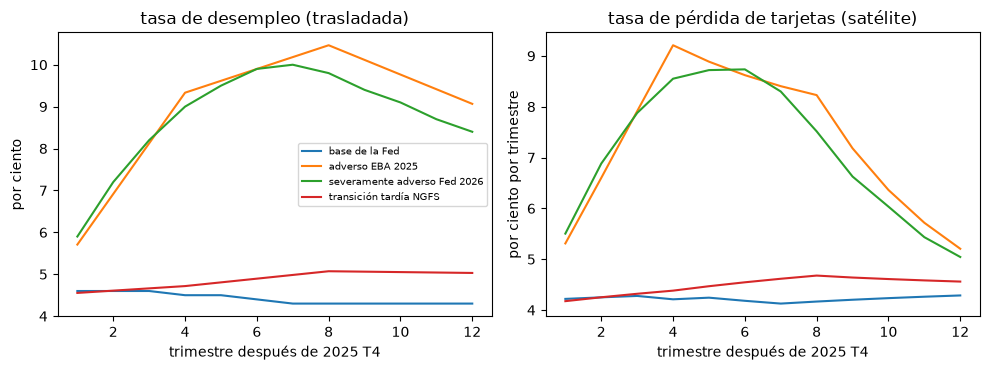

tasa de pérdida máxima de tarjetas por escenario: {'base de la Fed': 4.29, 'adverso EBA 2025': 9.21, 'severamente adverso Fed 2026': 8.73, 'transición tardía NGFS': 4.68}


In [11]:
# Dibujar las trayectorias de desempleo trasladadas y la tasa de tarjetas que implica cada escenario a través del satélite
cards = next(m for m in models["satellites"] if m["fed_loan_type"] == "credit-cards")
card_fit = satellite_fit(cards)
card_last = satellites.link("probit", np.array([last_rate["credit-cards"]]))
LABEL = {"baseline": "base de la Fed", "eba": "adverso EBA 2025", "fed": "severamente adverso Fed 2026", "ngfs": "transición tardía NGFS"}
quarters = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
implied = {}
for key in docs:
    p_u, p_g = path_of(key, "unemployment_rate"), path_of(key, "real_gdp_growth")
    unemployment_path = np.array([row["value"] for row in p_u["transposed"]])
    x_path = np.column_stack([[row["value"] for row in p_g["transposed"]], unemployment_path])
    start = np.array([[p_g["transposition"]["target"]["value"], p_u["transposition"]["target"]["value"]]])
    implied[key] = satellites.project_scenario(card_fit, card_last, start, x_path).rates
    axes[0].plot(quarters, unemployment_path, label=LABEL[key])
    axes[1].plot(quarters, implied[key] * 100, label=LABEL[key])
axes[0].set_title("tasa de desempleo (trasladada)")
axes[0].set_ylabel("por ciento")
axes[1].set_title("tasa de pérdida de tarjetas (satélite)")
axes[1].set_ylabel("por ciento por trimestre")
for ax in axes:
    ax.set_xlabel("trimestre después de 2025 T4")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("tasa de pérdida máxima de tarjetas por escenario:", {LABEL[k]: round(float(v.max()) * 100, 2) for k, v in implied.items()})

- **Toda añada es igual o anterior a la fecha de observación, 2026-08-31** (Reserva Federal 2026-02-04, EBA 2025-02-26, NGFS 2024-11-01), y el motor rechaza una trayectoria fechada 2026-09-30.
- **El motor reproduce los cuatro traslados versionados.** La trayectoria de la Reserva Federal no cambia por construcción (desempleo de 5,9 por ciento en el primer trimestre a un máximo de 10,0 en el séptimo). Los niveles anuales de la EBA pasan a 12 trimestres y suben 0,42 puntos de desempleo y bajan 1,76 puntos de crecimiento del PIB al punto de partida del banco (máximos de 10,47 por ciento de desempleo y un mínimo de crecimiento de -6,82). Los niveles de la NGFS son base más desviación (desempleo 4,547; 4,902 y 4,861 por ciento; la tasa de política baja entre 0,57 y 0,60 puntos) para la ventana 2031 a 2033. Cada una iguala la trayectoria versionada.
- **El satélite es una ecuación simple.** Para los préstamos comerciales e industriales el primer trimestre proyectado es la suma de seis términos (el término autorregresivo, -2,42, domina; el desempleo suma 0,42 y su rezago devuelve 0,37) y da una tasa de 0,007894, el valor versionado. Los cinco satélites reproducen los doce trimestres versionados con una brecha máxima de 0, con $R^2$ entre 0,910 y 0,959 sobre 115 a 139 observaciones; la mayor tasa trimestral proyectada es 8,73 por ciento para tarjetas de crédito y 1,14 por ciento para hipotecas residenciales.
- **La pérdida de crédito del banco sigue exactamente:** CLP 86.518,6; 111.986,8 y 71.005,1 millones en los tres años del escenario severamente adverso, iguales al bloque versionado, con las tasas de clase iguales a las tasas por tipo de préstamo ponderadas.
- **El pronóstico condicional del VAR corre pero no es el satélite.** Condicionado a que la tasa de tarjetas siga la trayectoria del satélite, la tasa C&I que implica llega a un máximo de 1,24 por ciento frente a 1,80 por ciento en el satélite C&I: dos modelos de la misma cantidad con muestras distintas (24 trimestres frente a 139) discrepan, lo cual es una razón para mantener un retador junto al campeón, no un resultado sobre ninguno.
- **El ajuste t asimétrico recupera una verdad conocida** (cuantiles normales con la desviación estándar de 2,281 del crecimiento del PIB devuelven $\alpha \approx 10^{-7}$ y $\sigma = 2,279$, con $\nu$ en el techo de búsqueda de 1000, una normal en el límite) y devuelve $\alpha = -1,83$, $\nu = 10,2$ para cuantiles de cola inferior pesada.
- **Los escenarios ordenan la tasa de pérdida de tarjetas como sugieren las trayectorias.** El máximo trimestral es 4,29 por ciento en la base de la Reserva Federal, 4,68 por ciento con la NGFS, 8,73 por ciento con el severamente adverso de la Reserva Federal y 9,21 por ciento con el adverso de la EBA, cuyo mínimo de PIB trasladado (-6,82) y máximo de desempleo (10,47) son más profundos que los de la Reserva Federal.

Lo que este cuaderno no muestra: los satélites se proyectaron, no se reajustaron (la historia de 1985 a 2019 no está versionada); el primer paso de regresiones cuantílicas del crecimiento en riesgo no se corrió; y ninguna de estas tasas es un pronóstico para Chile, porque trayectorias y coeficientes son de Estados Unidos trasladados a un banco sintético.

## Resumen

- Una prueba de estrés macro tiene tres capas; este cuaderno cubrió las trayectorias de escenario y los satélites, y el cuaderno 05 cubre el motor de capital.
- Una trayectoria publicada después de la fecha de observación la rechaza `check_vintage`; toda añada versionada es igual o anterior a ella.
- Una trayectoria publicada se lleva al punto de partida del banco conservando su forma: tal cual para la Reserva Federal, tras unir de anual a trimestral para la EBA, y como base más desviación para la NGFS. El motor reproduce cada trayectoria versionada.
- Un satélite probit es una regresión del ciclo crediticio latente sobre variables macro; con los coeficientes versionados el motor reproduce exactamente las tasas de pérdida versionadas y la pérdida de crédito del banco por año, pero los satélites no pueden reajustarse desde los archivos versionados.
- El pronóstico condicional de un VAR y el ajuste t asimétrico del crecimiento en riesgo son herramientas del motor que el caso no hornea; su mecánica se corrió sobre datos versionados y verdad conocida, y las regresiones cuantílicas del crecimiento en riesgo necesitan `statsmodels` y una serie de condiciones financieras que este entorno no tiene.

**Qué probar a continuación.** Cambia el escenario del paso 5 por el de la EBA y compara las tasas de pérdida máximas de los cinco tipos de préstamo. Luego sigue con el cuaderno 05, que toma las pérdidas y construye el plan de capital.

## Referencias

- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- NGFS (2024), Escenarios climáticos, Fase V (lanzamiento). https://www.ngfs.net/en/news/ngfs-scenarios-phase-v-launch-event
- Escenarios NGFS Fase V, IIASA Scenario Explorer (las corridas de NiGEM que lee el caso). https://data.ene.iiasa.ac.at/ngfs
- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Board of Governors of the Federal Reserve System (2026), escenario supervisor severamente adverso 2026, doméstico (el archivo de la trayectoria macro trimestral). https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_Severely_Adverse_Domestic.csv
- Dossiers 04 (I.1, el satélite y el enlace de Vasicek) y 05 (H.1 y H.2, las tres capas, el VAR y el crecimiento en riesgo) de la investigación persistida de Contraste, resumidos en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (las funciones de trayectoria, satélite y modelos de escenario).